# Plot color palette for dark and light mode

In [2]:

import matplotlib.pyplot as plt

PLOT_COLORS = {
    "light": [
        "#1762A0", "#A64600", "#006D69",
        "#7840A4", "#886000"
    ],
    "dark": [
        "#67B4F2", "#FFAB66", "#53D5C3",
        "#C39BF5", "#F4D45D"
    ]
}

LINESTYLES = ["-", "--", ":", "-.", (0, (8, 3))]
MARKERS = ["o", "s", "^", "D", "x"]

def setup_plot(mode="light"):
    dark = mode == "dark"
    bg = "#17191F" if dark else "#FFFFFF"
    fg = "#F0F0F0" if dark else "#202020"

    plt.rcParams.update({
        "figure.facecolor": bg,
        "axes.facecolor": bg,
        "savefig.facecolor": bg,
        "text.color": fg,
        "axes.labelcolor": fg,
        "xtick.color": fg,
        "ytick.color": fg,
        "axes.edgecolor": fg,
        "grid.alpha": 0.18,
        "axes.prop_cycle": plt.cycler(
            color=PLOT_COLORS[mode]
        )
    })

    return PLOT_COLORS[mode]

# Plot Setup
colors = setup_plot("light")

# Für mehrere Messreihen:
# ax.plot(x, y, color=colors[i],
#         linestyle=LINESTYLES[i],
#         marker=MARKERS[i])


# Task 3

Modify the 1D Ising code. Changes to be made to
| Function   | Modification | Status |
|------------|--------------|--------|
|`delta_H()` | Account for 4 nearest neighbours instead of 2 |&#x2611;|
| `metropolis_step()` | select site using two indices |&#x2611;|
| `metropolis_sweep()` | Visit every lattice site exactly once per sweep |&#x2611;|
| `magnetization()` | No change |&#x2611;|
| `run_simulation()` | Initialize $N_x\times N_y$ spin array |&#x2611;|
| `autocorrelation()` | No change |&#x2611;|

Then estimate $\langle m \rangle$ as a function of $h\in\left[ -1,1 \right]$ for fixed $J = \{0.3, J_c, 0.7\}$. Use $N_x=N_y \in [4, 20]$

Finished J=0.300, L=4, mean magnetizations:-0.972, -0.958, -0.932, -0.873, -0.731, -0.724, -0.677, -0.629, -0.579, -0.491, -0.397, -0.269, -0.141, -0.005, 0.156, 0.275, 0.388, 0.488, 0.577, 0.629, 0.682, 0.713, 0.734, 0.879, 0.928, 0.958, 0.972
Finished J=0.300, L=8, mean magnetizations:-0.972, -0.957, -0.929, -0.874, -0.730, -0.732, -0.706, -0.665, -0.607, -0.532, -0.447, -0.339, -0.185, -0.007, 0.172, 0.338, 0.443, 0.540, 0.605, 0.649, 0.698, 0.737, 0.735, 0.874, 0.928, 0.958, 0.973
Finished J=0.300, L=12, mean magnetizations:-0.972, -0.956, -0.930, -0.875, -0.740, -0.734, -0.702, -0.661, -0.606, -0.542, -0.443, -0.327, -0.181, -0.010, 0.173, 0.335, 0.448, 0.534, 0.602, 0.654, 0.703, 0.733, 0.735, 0.875, 0.929, 0.957, 0.972
Finished J=0.300, L=16, mean magnetizations:-0.973, -0.957, -0.929, -0.873, -0.733, -0.734, -0.700, -0.656, -0.604, -0.536, -0.441, -0.325, -0.171, 0.007, 0.177, 0.330, 0.449, 0.537, 0.604, 0.658, 0.698, 0.733, 0.734, 0.875, 0.929, 0.957, 0.973
Finished J=0.300, L

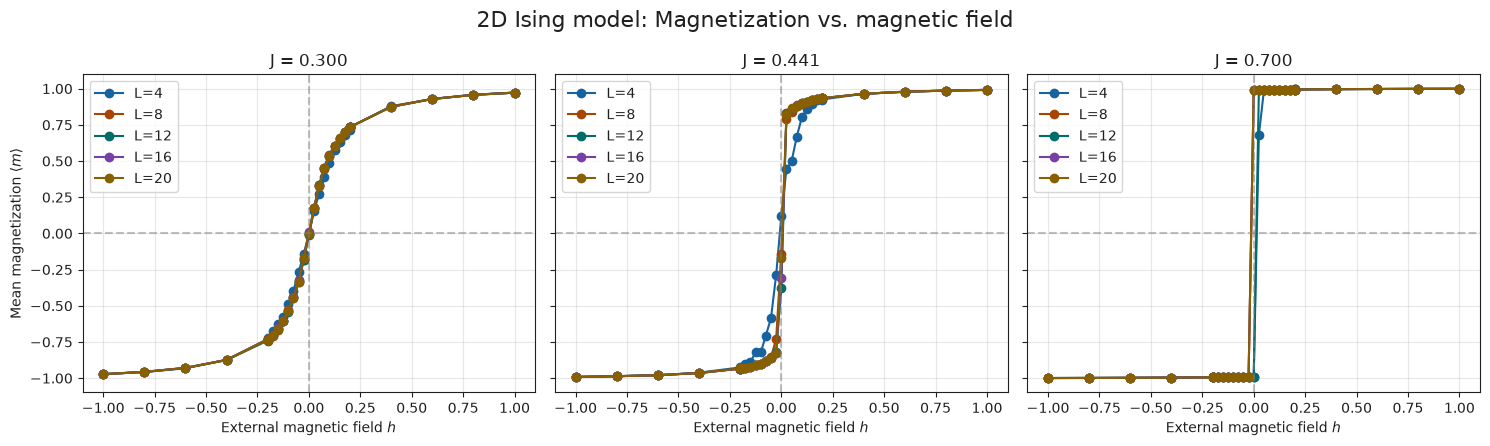

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Define some functions for the 1D Ising model 

def delta_H(spins, x, y, J=1.0, h=0.0):
    """Energy change when flipping spin (x,y)"""
    Nx, Ny = spins.shape # .shape returns a tuple of the dimensions of the array

    # Four nearest neighbours with periodic boundary conditions
    left = spins[(x - 1) % Nx, y]
    right = spins[(x + 1) % Nx, y]
    up = spins[x, (y - 1) % Ny]
    down = spins[x, (y + 1) % Ny]

    # Sum of nearest neighbours
    neighbour_sum = left+right+up+down

    # return energy difference dH
    return 2 * spins[x, y] * (J * neighbour_sum + h)

def metropolis_step(spins, x, y, T, rng, J=1.0, h=0.0): 
    """Attempt to flip spin (x,y) using Metropolis rule"""

    # Calculate local energy difference
    dH = delta_H(spins, x, y, J, h)

    # Apply Metropolis acceptance rule
    if dH <= 0 or rng.random() < np.exp(-dH / T):
        spins[x, y] *= -1

def metropolis_sweep(spins, T, rng, J=1.0, h=0.0):
    """Perform one full sweep of the 2D lattice"""
    Nx, Ny = spins.shape 

    for x in range(Nx):
        for y in range(Ny):
            metropolis_step(spins, x, y, T, rng, J, h)

def magnetization(spins):
    """Calculate the magnetization per spin m = sum(spins) / (Nx * Ny)"""
    return np.mean(spins)

def run_simulation(Nx, Ny, T, n_therm, n_meas, rng, J=1.0, h=0.0):
    """Run Metropolis sim for 2D Ising model"""

    # init all spins to +1
    # spins = np.ones((Nx, Ny), dtype=int) ## doesnt work: traps in metastable state for h<0 and strong J with positive magnetization

    # Initialize according to external field h
    # explanation see PDF
    if h > 0:
        spins = np.ones((Nx, Ny), dtype=int) # All spins up
    elif h < 0:
        spins = -np.ones((Nx, Ny), dtype=int) # All spins down
    else:
        spins = rng.choice([-1, 1], size=(Nx, Ny)) # Random initial configuration for h=0

    # Thermalization
    thermal_history = np.empty(n_therm)

    for k in range(n_therm):
        metropolis_sweep(spins, T, rng, J, h)
        thermal_history[k] = magnetization(spins)

    # Measurement 
    measurements = np.empty(n_meas)

    for k in range(n_meas):
        metropolis_sweep(spins, T, rng, J, h)
        measurements[k] = magnetization(spins)

    meas_mean = np.mean(measurements)

    return meas_mean, measurements, thermal_history

# ============================================================
# Task 3: Megnetization <m> as function of magnetic field h

J_c = 0.5 * np.log(1 + np.sqrt(2))  # critical coupling value

J_vals = [0.3, J_c, 0.7] # different coupling values
L_vals = [4, 8, 12, 16, 20] # different lattice sizes
h_vals = np.unique(np.concatenate([
    np.linspace(-1, 1, 11), # magnetic field values
    np.linspace(-0.2, 0.2, 17) # more values around h=0
]))

T = 1.0
n_therm = 2000
n_meas = 5000

rng = np.random.default_rng(seed=42)

# Store results in a dict
results = {}

for J in J_vals:
    results[J] = {}

    for L in L_vals:
        mean_values = []

        for h in h_vals:
            mean_m, measurements, _thermal_history = run_simulation(
                Nx = L,
                Ny = L,
                T = T,
                n_therm = n_therm,
                n_meas = n_meas,
                rng = rng,
                J = J,
                h = h
            )
            mean_values.append(float(mean_m))

        results[J][L] = mean_values
        print(f"Finished J={J:.3f}, L={L}, mean magnetizations:" 
              + ", ".join(f"{m:.3f}" for m in mean_values))

# Plotting
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)

for ax, J in zip(axes, J_vals):
    for L in L_vals:
        ax.plot(h_vals, results[J][L], label=f"L={L}", marker="o", color=colors[L_vals.index(L)])
    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
    ax.axvline(0, color="gray", linestyle="--", alpha=0.5)
    
    ax.set_title(f"J = {J:.3f}")
    ax.set_xlabel("External magnetic field $h$")
    ax.grid(alpha=0.3)
    ax.legend()


axes[0].set_ylabel(r"Mean magnetization $\langle m\rangle$")

fig.suptitle("2D Ising model: Magnetization vs. magnetic field", fontsize=16)
plt.tight_layout()
plt.show()



# # ============================================================
# # Statistical uncertainty and autocorrelation

# def autocorrelation(measurements, lag):
#     """Estimate the normalized autocorrelation at a given lag."""
#     m = np.asarray(measurements)
    
#     if lag == 0:
#         return 1.0
    
#     return np.corrcoef(m[:-lag], m[lag:])[0, 1]


# # Sample statistics
# M = len(measurements)
# sample_std = np.std(measurements, ddof=1)
# sem_naive = sample_std / np.sqrt(M)

# # Autocorrelation analysis
# max_lag = 100
# lags = np.arange(max_lag + 1)

# ac_values = np.array([
#     autocorrelation(measurements, lag) for lag in lags
#     ])

# # Integrated autocorrelation time
# cutoff = 75
# tau_int = 0.5 + np.sum(ac_values[1:cutoff + 1])

# # Effective sample size and corrected uncertainty
# M_eff = M / (2 * tau_int)
# sem_corrected = sample_std / np.sqrt(M_eff)

# # Results
# print(f"Mean magnetization:       {mean_m:.6f}")
# print(f"Sample standard deviation: {sample_std:.6f}")
# print(f"Naive SEM:                {sem_naive:.6f}")
# print(f"Autocorrelation time:     {tau_int:.4f} sweeps")
# print(f"Effective sample size:   {M_eff:.2f}")
# print(f"Corrected SEM:            {sem_corrected:.6f}")

# print(f"\nFinal estimate: <m> = {mean_m:.4f} ± {sem_corrected:.4f}")

# # Check sensitivity to the autocorrelation cutoff
# for c in [50, 75, 100]:
#     tau = 0.5 + np.sum(ac_values[1:c + 1])
#     print(f"Cutoff {c:3d}: tau_int = {tau:.3f}")

In [4]:
print(f"h_vals:\n {h_vals}")

h_vals:
 [-1.    -0.8   -0.6   -0.4   -0.2   -0.2   -0.175 -0.15  -0.125 -0.1
 -0.075 -0.05  -0.025  0.     0.025  0.05   0.075  0.1    0.125  0.15
  0.175  0.2    0.2    0.4    0.6    0.8    1.   ]


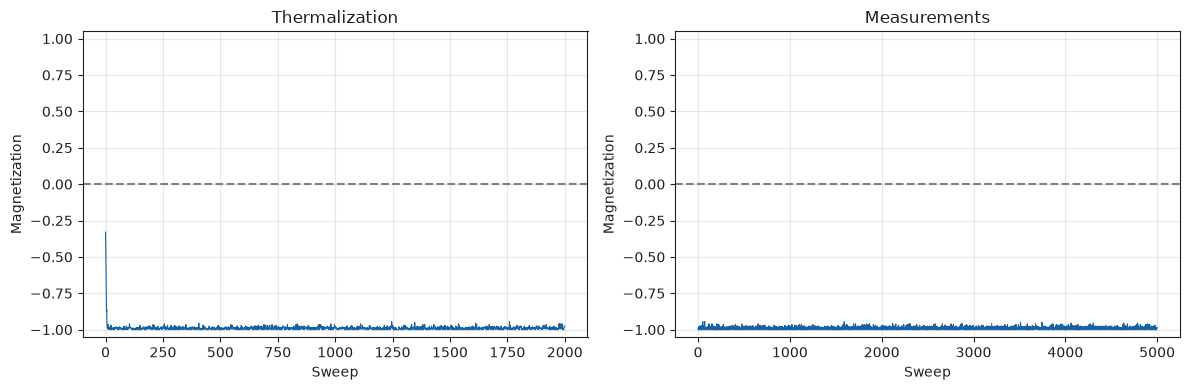

Mean magnetization: -0.9904


In [5]:
# test magnetization history at h = 0
# Plz ignore this part, it was just for testing and debugging

rng_test = np.random.default_rng(seed=123)

mean_m, measurements, thermal_history = run_simulation(
    Nx=20,
    Ny=20,
    T=1.0,
    n_therm=2000,
    n_meas=5000,
    rng=rng_test,
    J=0.7,
    h=0.0
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(thermal_history, linewidth=0.8)
axes[0].set_title("Thermalization")
axes[0].set_xlabel("Sweep")
axes[0].set_ylabel("Magnetization")

axes[1].plot(measurements, linewidth=0.8)
axes[1].set_title("Measurements")
axes[1].set_xlabel("Sweep")
axes[1].set_ylabel("Magnetization")

for ax in axes:
    ax.set_ylim(-1.05, 1.05)
    ax.axhline(0, color="gray", linestyle="--")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Mean magnetization: {mean_m:.4f}")

# Task 4

Use algorithm to estimate $\langle\epsilon\rangle = \frac{\langle H\rangle}{n_xN_y}$ (average energy per site) as a function of $J\in \left[ 0.25,2 \right]$ for $h=0$. Use Use $N_x=N_y \in [4, 20]$.

With $h=0$ we simplify 
$$H = -J\sum_{\langle i,j \rangle} s_is_j.$$
To avoid double counting (e.g. interaction between $s_A$ and $s_B$ is the same as $s_B$ and $s_A$) we only consider the neighbour to the right and below each spin. This way we can write 
$$H = -J \sum_{x=0}^{N_{x-1}}\sum_{y=0}^{N_{y-1}} s_{x,y}\left( s_{x+1,y} + s_{x,y+1} \right)$$

Needed to modify code, because some values were suspicious:
- $L=20$, $J=2.00$ got $-3.380$ ($-4.000$ expected)
- $L=12$, $J=1.93$ got $-2.975$ ($-3.854$ expected)
- $L=16$, $J=1.64$ got $-3.157$ ($-3.271$ expected)

Likely cause: initialization of values with 
`spins = rng.choice([-1,1], size=(Nx, Ny))` changed to
`spins = np.ones((Nx, Ny), dtype=int)`

Random initialization can create large domains seperated by walls. At strong coupling $J$, configurations can persist for many Metropolis sweeps because removing domain walls can require energetically unfavourable spin flips.
Starting from an ordered state avoids initial domain walls and improves equlibration of energy at large J

This is different to task 3, because there field-aligned initialization helps avoid metastable states (explained in PDF)

In [6]:
def energy_per_spin(spins, J=1.0, h=0.0):
    """Calc total energy divided by number of spins"""

    Nx, Ny = spins.shape # .shape returns a tuple of the dimensions of the array

    H = 0.0 # started from the bottom

    for x in range(Nx):
        for y in range(Ny):

            # periodic nearest neighbours
            right = spins[(x + 1) % Nx, y]
            down = spins[x, (y + 1) % Ny]

            H += -J * spins[x, y] * (right + down) # add em up

    H -= h * np.sum(spins) # subtract external field contribution

    return H / (Nx * Ny)

# Test
spins = np.ones((4, 4), dtype=int) # all spins up
E_before = energy_per_spin(spins, J=1.0, h=0.0)
dH = delta_H(spins, 1, 1, J=1.0, h=0.0) # energy change for flipping one spin
spins[1,1] *= -1 # flip the spin
E_after = energy_per_spin(spins, J=1.0, h=0.0)
print(f"Energy change from delta_H: {dH:.4f}")
print(f"Actual energy change: {(E_after - E_before) * spins.size:.4f}")


def run_energy_simulation(Nx, Ny, T, n_therm, n_meas, rng, J=1.0, h=0.0):
    """Run 2D Ising sim and measure energy per spin"""

    # Random init config
    # spins = rng.choice([-1,1], size=(Nx, Ny))
    # 
    spins = np.ones((Nx, Ny), dtype=int) # all spins up

    # Thermalization
    for i in range(n_therm):
        metropolis_sweep(spins, T, rng, J, h)

    # Energy measurements
    energies = np.empty(n_meas)

    for k in range(n_meas):
        metropolis_sweep(spins, T, rng, J, h)
        energies[k] = energy_per_spin(spins, J, h)

    # return mean energy and all measurements
    return np.mean(energies), energies

# ============================================================
# Task 4: mean energy per spin as function of J

J_vals = np.linspace(0.25, 2.0, 25) # coupling values between 0.25 and 2.0
L_vals = [4, 8, 12, 16, 20] # different lattice sizes

T = 1.0
h = 0.0

n_therm = 1000
n_meas = 3000

rng = np.random.default_rng(seed=42)

results_energy = {}

# run dis shiet
for L in L_vals:
    mean_energies = []

    for J in J_vals:
        mean_E, _energies = run_energy_simulation(
            Nx=L,
            Ny=L,
            T=T,
            n_therm=n_therm,
            n_meas=n_meas,
            rng=rng,
            J=J,
            h=h
        )
        mean_energies.append(float(mean_E))

    results_energy[L] = mean_energies
    print(f"Finished L={L}, mean energies:" 
          + ", ".join(f"{E:.3f}" for E in mean_energies))

Energy change from delta_H: 8.0000
Actual energy change: 8.0000
Finished L=4, mean energies:-0.159, -0.319, -0.534, -0.787, -0.995, -1.191, -1.349, -1.505, -1.658, -1.807, -1.955, -2.103, -2.250, -2.395, -2.542, -2.688, -2.833, -2.979, -3.125, -3.271, -3.417, -3.562, -3.708, -3.854, -4.000
Finished L=8, mean energies:-0.142, -0.255, -0.473, -0.770, -0.997, -1.181, -1.348, -1.505, -1.657, -1.806, -1.954, -2.103, -2.249, -2.395, -2.541, -2.687, -2.833, -2.979, -3.125, -3.271, -3.417, -3.562, -3.708, -3.854, -4.000
Finished L=12, mean energies:-0.140, -0.255, -0.445, -0.756, -0.995, -1.180, -1.347, -1.505, -1.656, -1.807, -1.955, -2.102, -2.249, -2.395, -2.541, -2.687, -2.833, -2.979, -3.125, -3.271, -3.417, -3.562, -3.708, -3.854, -4.000
Finished L=16, mean energies:-0.138, -0.253, -0.433, -0.766, -0.997, -1.181, -1.348, -1.504, -1.657, -1.807, -1.955, -2.102, -2.249, -2.395, -2.541, -2.687, -2.833, -2.979, -3.125, -3.271, -3.417, -3.562, -3.708, -3.854, -4.000
Finished L=20, mean energi

J = 0.25, exact energy = -0.139318
J = 0.70, exact energy = -1.374643
J = 1.00, exact energy = -1.997160
J = 2.00, exact energy = -3.999998
J = 0.44, exact energy = -0.623225


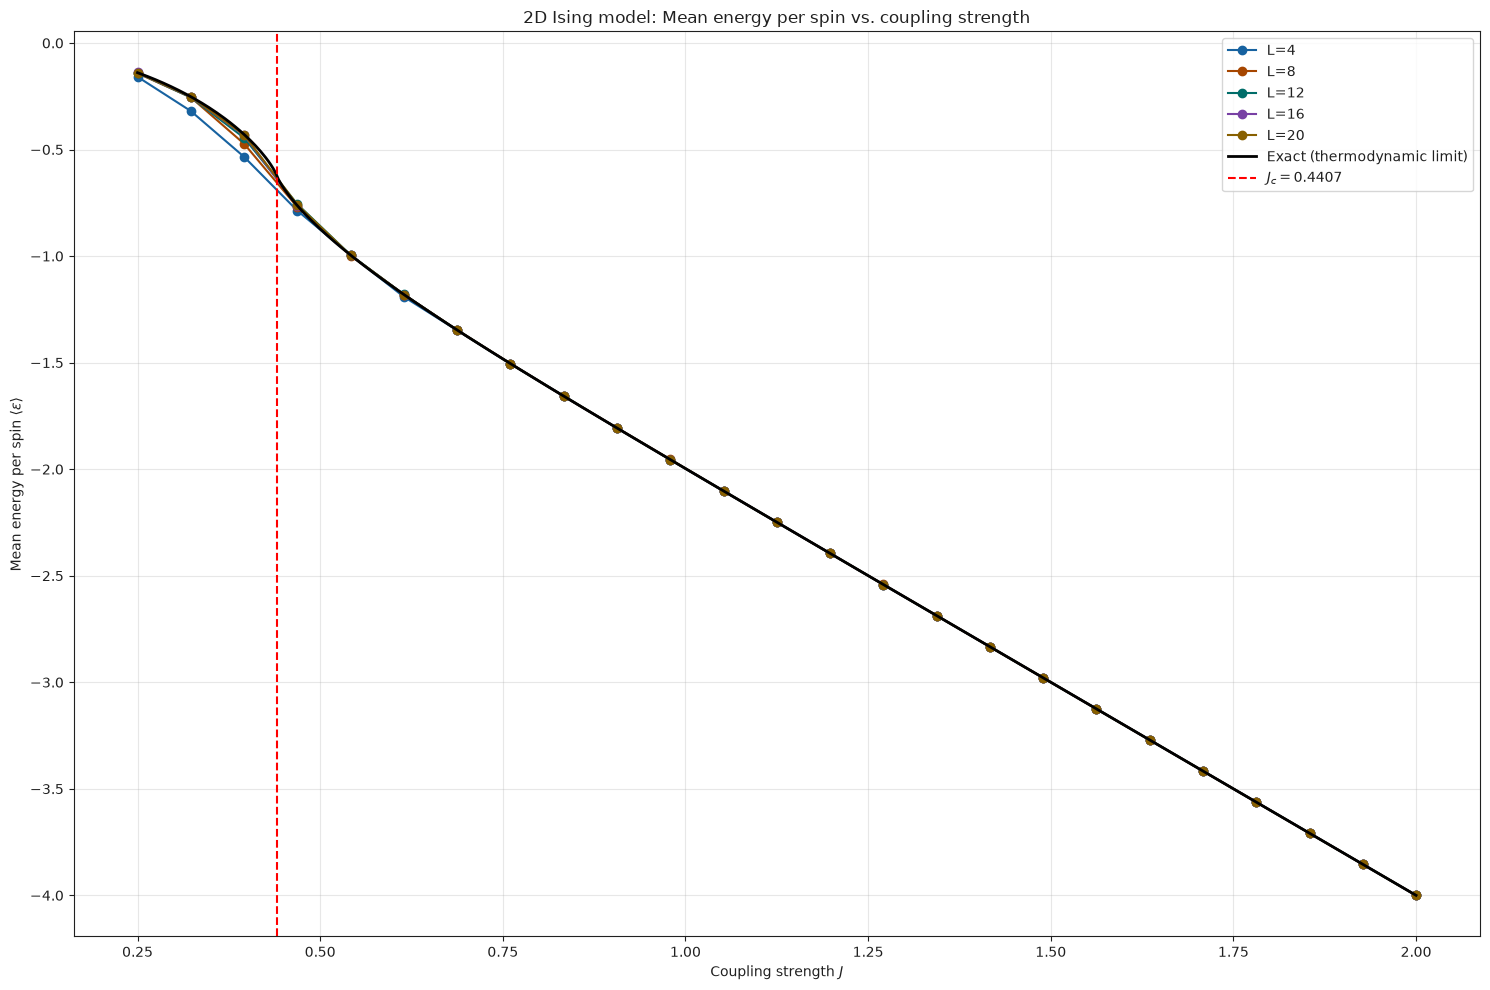

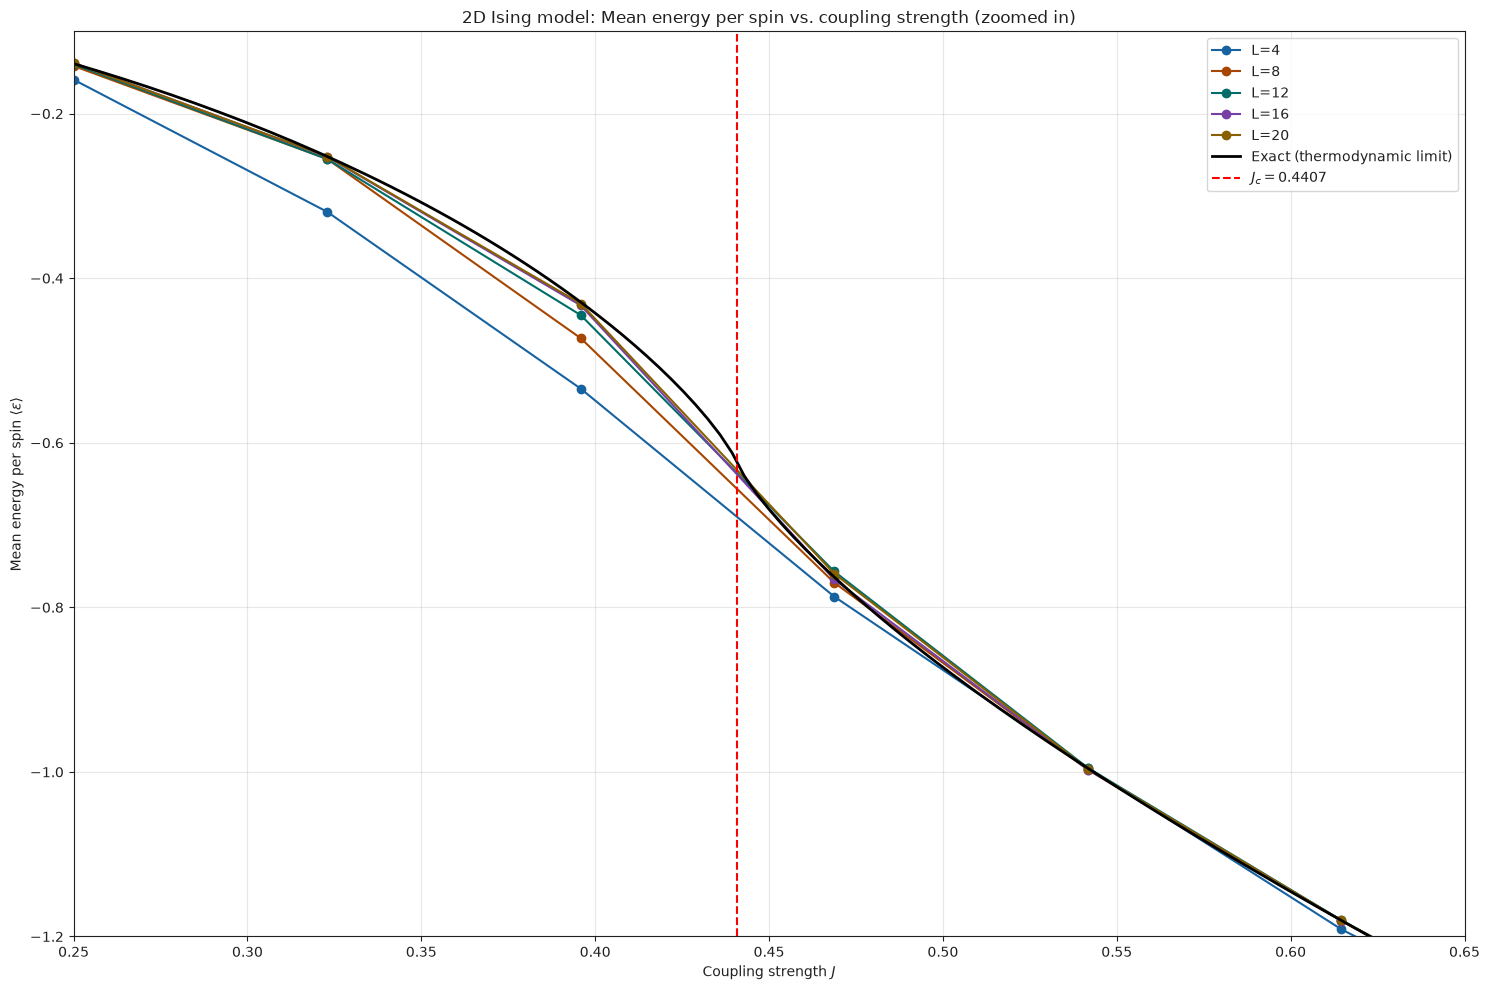

In [7]:
# Comparison to exact solution in the thermodynamic limit and plotting
from scipy.special import ellipk

def exact_energy_per_spin(J):
    """Exact energy per spin for the infinite 2D Ising model at T=1 and h=0"""

    J_c = 0.5 * np.log(1 + np.sqrt(2))  # critical coupling value (special case)

    # Handle critical point separately to avoid division by zero or singularities
    if np.isclose(J, J_c, rtol=0, atol=1e-12): # Check if J is close to the critical value with a small tolerance
        return -np.sqrt(2) * J_c
    
    k = 2 * np.sinh(2 * J) / (np.cosh(2 * J) ** 2)
    m = k**2 # because scipy's ellipk function defines ellipk(m) = K(\sqrt(m)) 

    coth = 1 / np.tanh(2 * J)

    # exact energy per spin
    energy = -J * coth * (1 + (2 / np.pi) * (2 * np.tanh(2 * J)**2 - 1) * ellipk(m))
    return energy

# Test
J_test = [0.25, 0.7, 1.0, 2.0, J_c] # shit maybe J_C special case? idk yet

for J in J_test:
    print(f"J = {J:.2f}, exact energy = {exact_energy_per_spin(J):.6f}")

# ============================================================
# Compare simulation results with exact solution

J_fine = np.linspace(0.25, 2.0, 500)

fig, ax = plt.subplots(figsize=(15, 10))

# Plot Monte Carlo results for each lattice size
for L in L_vals:
    ax.plot(J_vals, results_energy[L], label=f"L={L}", marker="o", color=colors[L_vals.index(L)])

# Plot the exact solution
ax.plot(J_fine, [exact_energy_per_spin(J) for J in J_fine], label="Exact (thermodynamic limit)", color="black", linewidth=2)

# Mark the critical coupling J_c
ax.axvline(J_c, color="red", linestyle="--", label=rf"$J_c = {J_c:.4f}$")

# # make zoomed inset for J near J_c with t
# from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
# axins = inset_axes(ax, width="40%", height="30%", loc="lower center", borderpad=2)
# axins.plot(J_vals, results_energy[4], label=f"L=4", marker="o", color=colors[0])
# axins.plot(J_vals, results_energy[8], label=f"L=8", marker="o", color=colors[1])
# axins.plot(J_vals, results_energy[12], label=f"L=12", marker="o", color=colors[2])
# axins.plot(J_vals, results_energy[16], label=f"L=16", marker="o", color=colors[3])
# axins.plot(J_vals, results_energy[20], label=f"L=20", marker="o", color=colors[4])
# axins.plot(J_fine, [exact_energy_per_spin(J) for J in J_fine], label="Exact", color="black", linewidth=2)
# axins.axvline(J_c, color="red", linestyle="--")
# axins.set_xlim(J_c - 0.2, J_c + 0.05)
# axins.set_ylim(-1, 0)
# mark_inset(ax, axins, loc1=1, loc2=3, fc="none", ec="0.5")


# ax.set_ylim(-5, 0.0)
ax.set_xlabel("Coupling strength $J$")
ax.set_ylabel(r"Mean energy per spin $\langle\epsilon\rangle$")
ax.set_title("2D Ising model: Mean energy per spin vs. coupling strength")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("energy_vs_J.pdf", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(15, 10))

# Plot Monte Carlo results for each lattice size
for L in L_vals:
    ax.plot(J_vals, results_energy[L], label=f"L={L}", marker="o", color=colors[L_vals.index(L)])
# zoomed in plot for J near J_c with inset
ax.plot(J_fine, [exact_energy_per_spin(J) for J in J_fine], label="Exact (thermodynamic limit)", color="black", linewidth=2)

# Mark the critical coupling J_c
ax.axvline(J_c, color="red", linestyle="--", label=rf"$J_c = {J_c:.4f}$")

ax.set_xlim(0.25, 0.65)
ax.set_ylim(-1.2, -0.1)
ax.set_xlabel("Coupling strength $J$")
ax.set_ylabel(r"Mean energy per spin $\langle\epsilon\rangle$")
ax.set_title("2D Ising model: Mean energy per spin vs. coupling strength (zoomed in)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("energy_vs_J_zoomed.pdf", dpi=300)
plt.show()

# Task 5

Use algorithm to estimate $\langle|m|\rangle$ (absolute value of mean magnetization) as a function of $J\in \left[ 0.25,2 \right]$ for $h=0$. Use Use $N_x=N_y \in [4, 20]$. Plot results as funciton of $J^{-1}$ and compare to exact solution in thermodynamic limit. 

In [ ]:
def run_absolute_magnetization_simulation(Nx, Ny, T, n_therm, n_meas, rng, J=1.0):
    """Measure the mean abs magnetization of the 2D Isaing model"""

    # Run existing simulation with h=0
    _, measurements, thermal_history = run_simulation(
        Nx=Nx,
        Ny=Ny,
        T=T,
        n_therm=n_therm,
        n_meas=n_meas,
        rng=rng,
        J=J,
        h=0.0
    )

    # Calculate the abs magnetization for each measurement
    abs_measurements = np.abs(measurements)

    # Return the mean abs magnetization and the abs measurements
    return np.mean(abs_measurements), abs_measurements, thermal_history

# ============================================================
# Task 5: Mean absolute magnetization <|m|> as function of J

J_c = 0.5 * np.log(1 + np.sqrt(2))  # critical coupling value
J_vals = np.linspace(0.25, 1.0, 31) # coupling values between 0.25 and 1.0
L_vals = [4, 8, 12, 16, 20] # different lattice sizes

T = 1.0
n_therm = 2000
n_meas = 5000

rng = np.random.default_rng(seed=42)

results_abs_magnetization = {}

for L in L_vals:
    mean_abs_vals = []

    for J in J_vals:
        mean_abs_m, abs_measurements, _thermal_history = run_absolute_magnetization_simulation(
            Nx=L,
            Ny=L,
            T=T,
            n_therm=n_therm,
            n_meas=n_meas,
            rng=rng,
            J=J
        )
        mean_abs_vals.append(float(mean_abs_m))

    results_abs_magnetization[L] = mean_abs_vals
    print(f"Finished L={L}, mean absolute magnetizations:" 
          + ", ".join(f"{m:.3f}" for m in mean_abs_vals))

Finished L=4, mean absolute magnetizations:0.425, 0.467, 0.524, 0.591, 0.640, 0.700, 0.776, 0.825, 0.856, 0.895, 0.920, 0.939, 0.952, 0.967, 0.975, 0.978, 0.984, 0.986, 0.990, 0.992, 0.994, 0.995, 0.997, 0.997, 0.998, 0.998, 0.998, 0.999, 0.999, 0.999, 0.999
Finished L=8, mean absolute magnetizations:0.209, 0.234, 0.272, 0.327, 0.394, 0.500, 0.588, 0.725, 0.803, 0.876, 0.912, 0.937, 0.957, 0.964, 0.975, 0.980, 0.983, 0.988, 0.990, 0.992, 0.994, 0.995, 0.995, 0.997, 0.998, 0.998, 0.998, 0.999, 0.999, 0.999, 0.999
Finished L=12, mean absolute magnetizations:0.140, 0.159, 0.184, 0.211, 0.266, 0.356, 0.484, 0.651, 0.799, 0.872, 0.910, 0.939, 0.953, 0.966, 0.973, 0.980, 0.984, 0.988, 0.990, 0.993, 0.994, 0.995, 0.996, 0.997, 0.997, 0.998, 0.998, 0.999, 0.999, 0.999, 0.999
Finished L=16, mean absolute magnetizations:0.102, 0.118, 0.135, 0.160, 0.200, 0.257, 0.381, 0.604, 0.782, 0.869, 0.908, 0.939, 0.953, 0.965, 0.974, 0.980, 0.984, 0.987, 0.990, 0.992, 0.994, 0.995, 0.996, 0.997, 0.997, 0.9

J = 0.2500, exact |m| = 0.000000
J = 0.4407, exact |m| = 0.000000
J = 0.5000, exact |m| = 0.911319
J = 0.7000, exact |m| = 0.990163
J = 1.0000, exact |m| = 0.999276


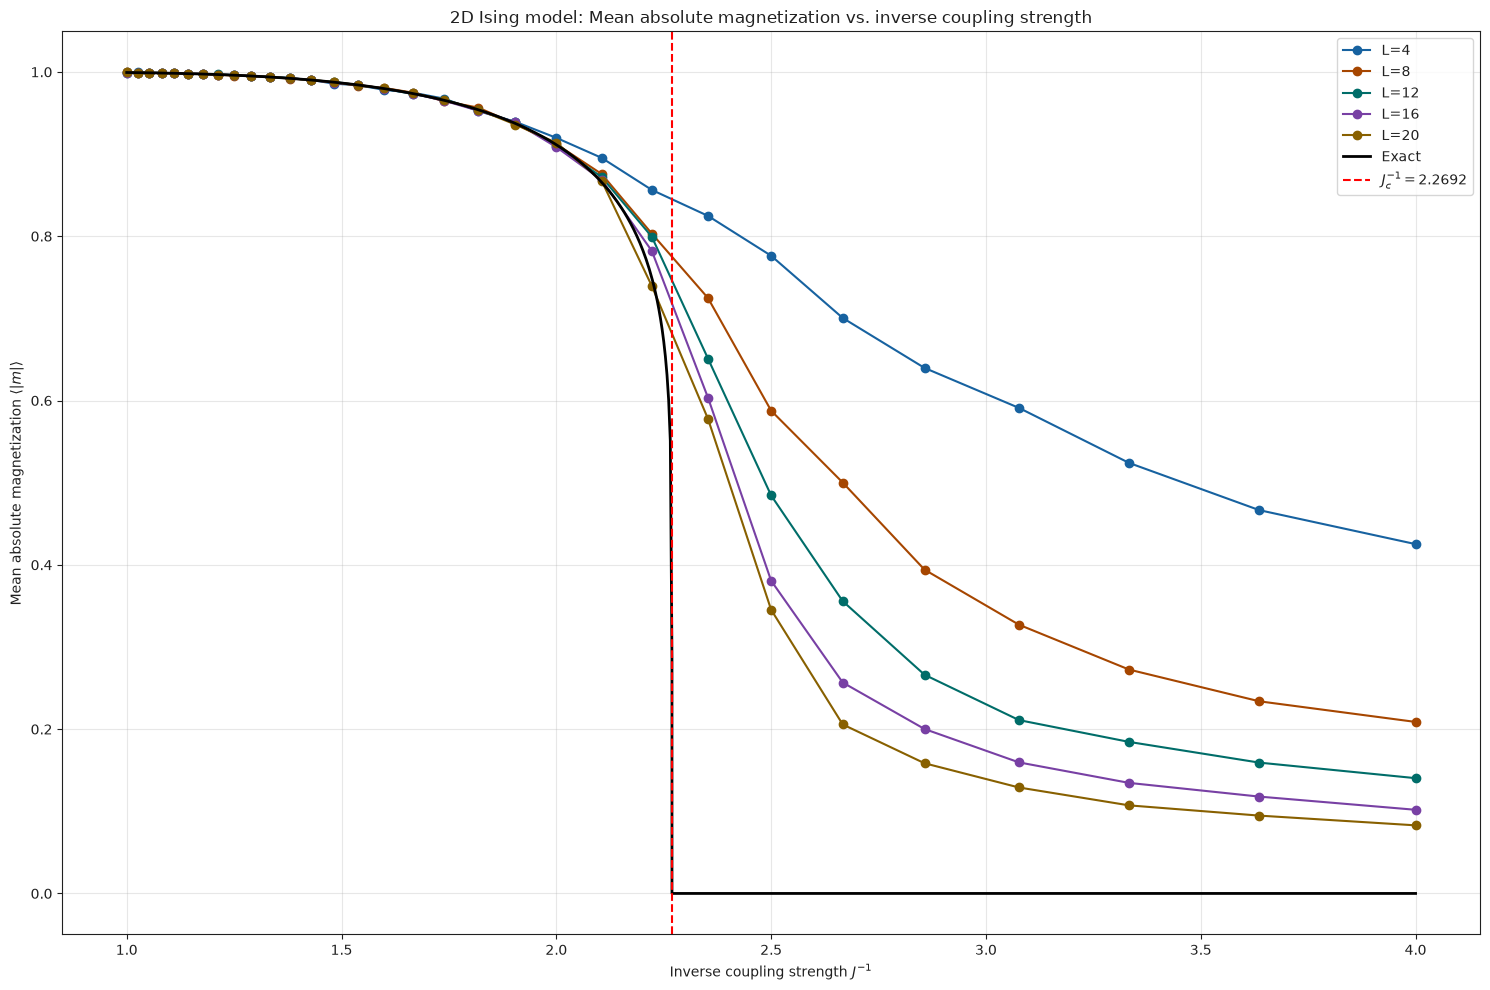

In [ ]:
# Comparison to exact solution in the thermodynamic limit and plotting
def exact_abs_magnetization(J):
    """Exactomundo in the thermodynamic limit"""

    J_c = 0.5 * np.log(1 + np.sqrt(2))  # critical coupling value

    if J<=J_c: 
        return 0.0

    return (1 - np.sinh(2 * J)**(-4))**(1/8)

# Test
J_test = [0.25, J_c, 0.5, 0.7, 1.0]

for J in J_test:
    print(f"J = {J:.4f}, exact |m| = {exact_abs_magnetization(J):.6f}")

# Plotting
# J_fine = np.linspace(0.25, 1.0, 500)
J_fine = np.sort(np.unique(np.concatenate([
    np.linspace(0.25, 1.0, 1000),
    [J_c] # Add the critical coupling value to the fine grid for better resolution around the critical point
])))

fig, ax = plt.subplots(figsize=(15, 10))

# Plot Monte Carlo results for each lattice size
for L in L_vals:
    ax.plot(1/J_vals, results_abs_magnetization[L], label=f"L={L}", marker="o", color=colors[L_vals.index(L)])

# Plot exact solution
ax.plot(1/J_fine, [exact_abs_magnetization(J) for J in J_fine], label="Exact", color="black", linewidth=2)

# Mark the critical coupling J_c
ax.axvline(1/J_c, color="red", linestyle="--", label=rf"$J_c^{{-1}} = {1/J_c:.4f}$")

ax.set_xlabel(r"Inverse coupling strength $J^{-1}$")
ax.set_ylabel(r"Mean absolute magnetization $\langle |m|\rangle$")
ax.set_title("2D Ising model: Mean absolute magnetization vs. inverse coupling strength")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("abs_mean_magnetization_vs_J.pdf", dpi=300)
plt.show()

# Task 6

Estimate specific heat $C = \Lambda(\langle\epsilon^2\rangle - \langle\epsilon\rangle^2)$ with $h=0$ as function of $J\in\left[0.25, 1\right]$ (i'm tired boss) for lattice sizes $N_x=N_y \in [0, 20]$. Plot result for $C/J^2$ as function of $J^{-1}$.

Bonus: compare to $C(\mathrm{thermod. limit})$

In [23]:
def specific_heat(energies, Nx, Ny):
    """Calc specific heat from energy-per-spin measurements"""

    # Total number of spins
    Lambda = Nx * Ny

    # average energy per spin
    mean_E = np.mean(energies)

    # average squared energy per spin
    mean_E2 = np.mean(energies**2)

    # specific heat
    C = Lambda * (mean_E2 - mean_E**2)

    return C

# # Sanity check
# test_energies = np.array([-1.0, -2.0, -1.0, -2.0])
# # C = 16(2.5-1.5^2) = 4
# print(specific_heat(test_energies, Nx=4, Ny=4)) # verdict: not insane

# ============================================================
# Task 6: Specific heat C as function of J^-1

J_c = 0.5 * np.log(1 + np.sqrt(2))  # critical coupling value

# J_vals = np.linspace(0.25, 1.0, 31) # coupling values between 0.25 and 1.0
J_vals = np.sort(np.unique(np.concatenate([
    np.linspace(0.25, 1.0, 31),
    np.linspace(0.38, 0.50, 25)
])))
L_vals = [4, 8, 12, 16, 20] # different lattice sizes

T = 1.0
h = 0.0
n_therm = 1000
n_meas = 3000

rng = np.random.default_rng(seed=42)

results_specific_heat = {}

for L in L_vals:
    specific_heat_vals = []

    for J in J_vals:
        mean_E, energies = run_energy_simulation(
            Nx=L,
            Ny=L,
            T=T,
            n_therm=n_therm,
            n_meas=n_meas,
            rng=rng,
            J=J,
            h=h
        )
        C = specific_heat(energies, Nx=L, Ny=L)

        # store C/J^2
        specific_heat_vals.append(float(C / J**2))
    results_specific_heat[L] = specific_heat_vals
    print(f"Finished L={L}, C/J^2 values:"
          + ", ".join(f"{C:.3f}" for C in specific_heat_vals))

Finished L=4, C/J^2 values:3.924, 4.475, 4.954, 5.304, 5.692, 5.518, 5.289, 5.433, 5.411, 5.220, 5.098, 4.897, 4.739, 4.704, 4.666, 4.378, 4.386, 4.041, 4.338, 4.031, 3.866, 3.837, 3.480, 3.492, 3.429, 2.961, 3.438, 2.804, 2.761, 2.477, 2.375, 2.359, 2.013, 1.396, 1.092, 0.845, 0.644, 0.490, 0.477, 0.303, 0.256, 0.205, 0.194, 0.118, 0.089, 0.097, 0.078, 0.053, 0.039, 0.029, 0.029, 0.020
Finished L=8, C/J^2 values:2.810, 3.037, 3.348, 4.075, 5.011, 6.225, 5.964, 6.346, 6.677, 6.885, 6.823, 7.066, 7.127, 6.749, 7.043, 6.560, 6.816, 6.191, 6.420, 6.263, 6.014, 5.096, 5.082, 5.129, 4.483, 4.189, 4.235, 3.679, 3.367, 3.265, 3.225, 2.547, 1.909, 1.485, 1.168, 0.823, 0.654, 0.520, 0.393, 0.319, 0.254, 0.206, 0.149, 0.126, 0.096, 0.083, 0.072, 0.052, 0.047, 0.037, 0.026, 0.023
Finished L=12, C/J^2 values:2.723, 3.043, 3.364, 3.352, 4.080, 5.521, 5.640, 5.883, 6.543, 6.576, 7.647, 7.202, 7.978, 7.930, 7.986, 7.959, 7.967, 7.965, 7.772, 7.429, 6.696, 5.927, 5.450, 5.333, 5.397, 4.175, 4.252, 4.1

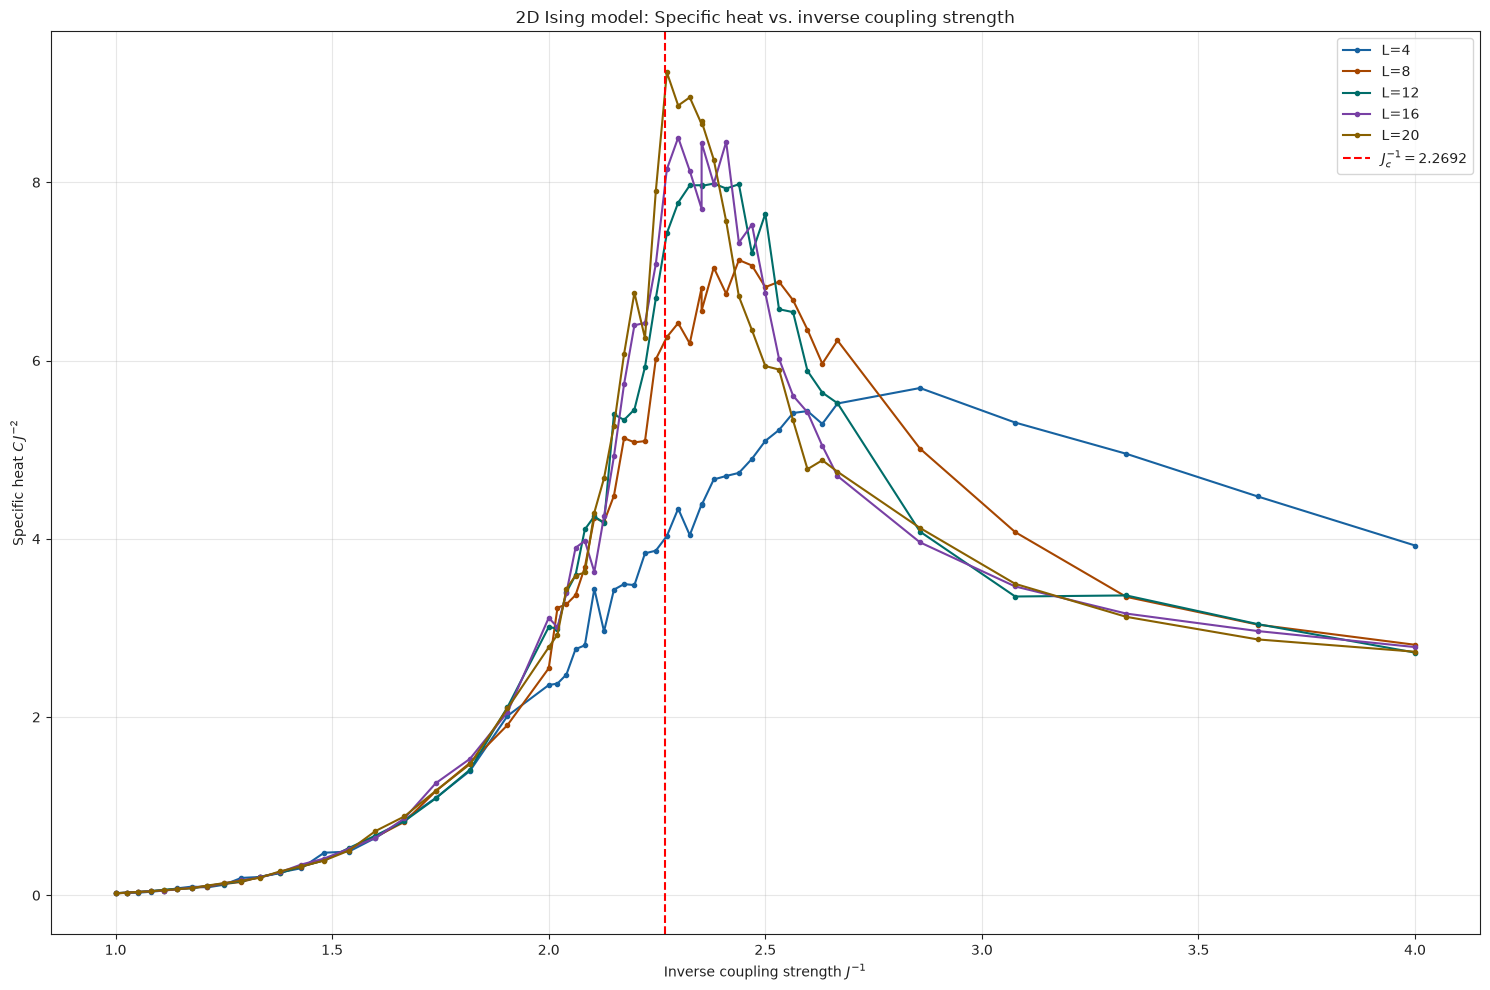

In [27]:
# ============================================================
# Specific heat vsd. inverse coupling

fig, ax = plt.subplots(figsize=(15, 10))

for L in L_vals:
    ax.plot(1/J_vals, results_specific_heat[L], label=f"L={L}", marker=".", color=colors[L_vals.index(L)])

# critical coupling value
ax.axvline(1/J_c, color="red", linestyle="--", label=rf"$J_c^{{-1}} = {1/J_c:.4f}$")

ax.set_xlabel(r"Inverse coupling strength $J^{-1}$")
ax.set_ylabel(r"Specific heat $C\,J^{-2}$")
ax.set_title("2D Ising model: Specific heat vs. inverse coupling strength")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("specific_heat_vs_J.pdf", dpi=300)
plt.show()

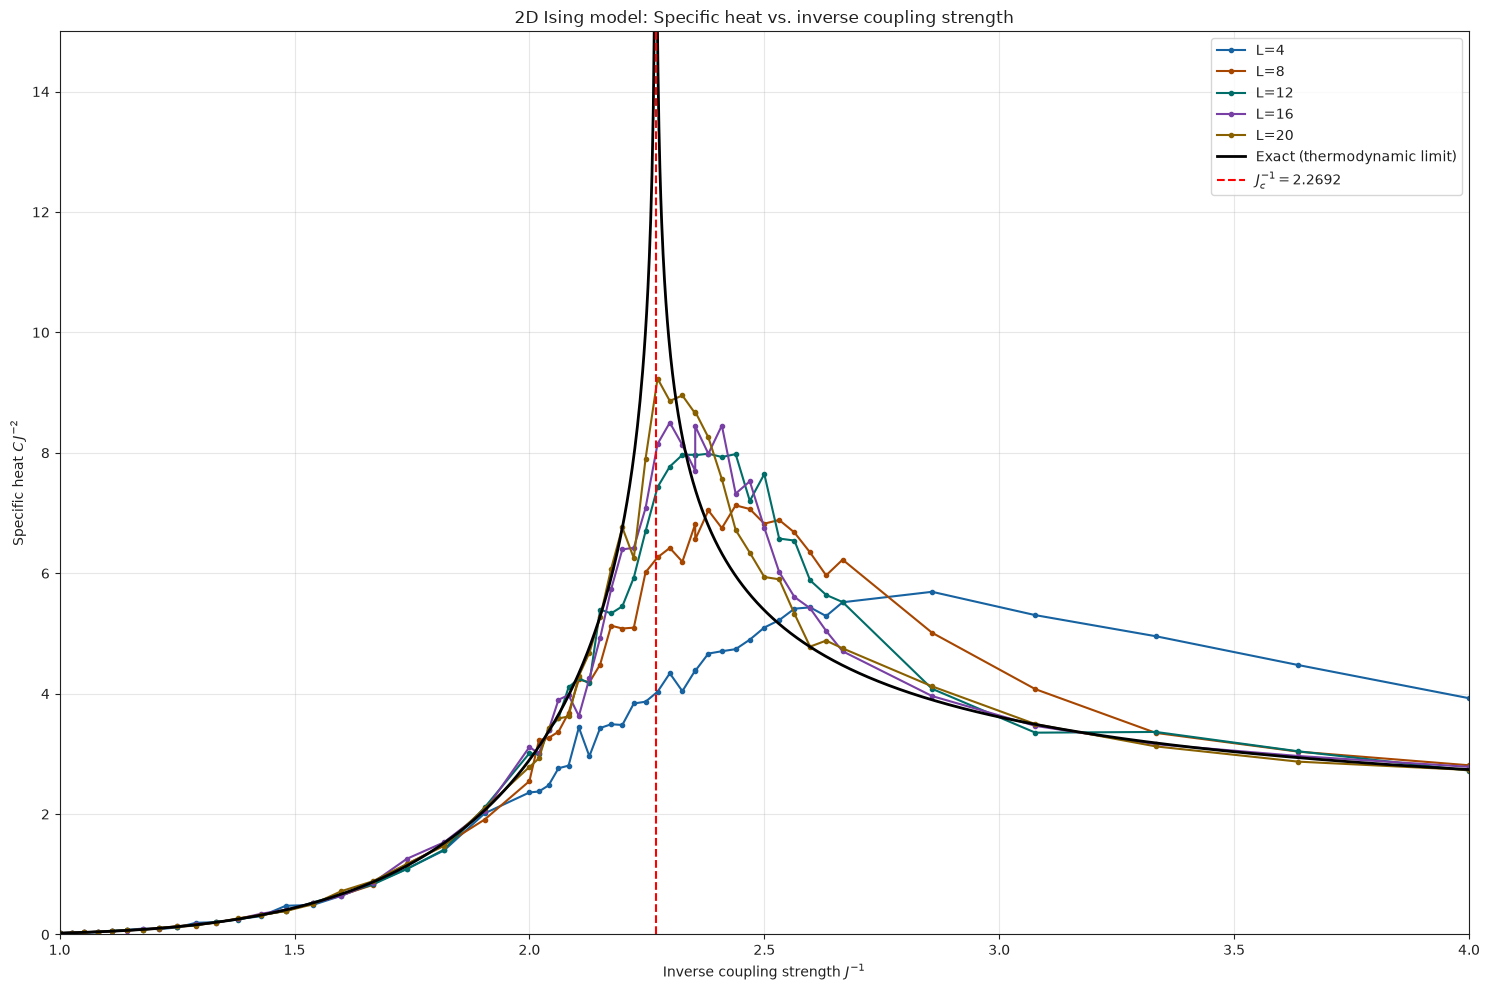

In [32]:
# ============================================================
# Bonus: Comparison with exact solution for specific heat in the thermodynamic limit
from scipy.special import ellipk, ellipe

def exact_specific_heat_overJ2(J):
    """Exact C/J^2 for the infinite 2D Ising model at T=1 and h=0"""

    J_c = 0.5 * np.log(1 + np.sqrt(2))

    # Specific heat diverges at the critical coupling
    if np.isclose(J, J_c, rtol=0, atol=1e-12):
        return np.inf

    t = np.tanh(2 * J)
    m = 4 * t**2 * (1 - t**2)

    K = ellipk(m)
    E = ellipe(m)

    return 2 * (1 - t**2) * (
        -1 / t**2
        + (2 / np.pi) * (
            (1 / t**2 - 2 + 4 / m) * K
            - (4 / m) * E
        )
    )

# avoid singularity at J_c by splitting the range into two parts
J_below = np.linspace(0.25, J_c-0.0005, 1000)
J_above = np.linspace(J_c+0.0005, 1.0, 1000)

fig, ax = plt.subplots(figsize=(15, 10))

# Monte carlo results
for L in L_vals:
    ax.plot(1/J_vals, results_specific_heat[L], label=f"L={L}", marker=".", color=colors[L_vals.index(L)])

# exact solution
ax.plot(1/J_below, [exact_specific_heat_overJ2(J) for J in J_below], label="Exact (thermodynamic limit)", color="black", linewidth=2)
ax.plot(1/J_above, [exact_specific_heat_overJ2(J) for J in J_above], color="black", linewidth=2)

# critical coupling value
ax.axvline(1/J_c, color="red", linestyle="--", label=rf"$J_c^{{-1}} = {1/J_c:.4f}$")

ax.set_xlim(1, 4)
ax.set_ylim(0, 15)
ax.set_xlabel(r"Inverse coupling strength $J^{-1}$")
ax.set_ylabel(r"Specific heat $C\,J^{-2}$")
ax.set_title("2D Ising model: Specific heat vs. inverse coupling strength")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("specific_heat_vs_J_with_exact.pdf", dpi=300)
plt.show()